In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv('business-news-caro.csv')
df.head()

,uri,canonical,country,sector,themes,sentence_id,polarity,doc_id,date,document_url,title
0,Date,2026-10-22,NaN,NaN,['finance'],1,NaN,C:\Users\LENOVO\Desktop\Projcet wowool\othmane...,['2026-10-22'],['https://help.bbc.com/hc/'],"['Barclays cutting 5,000 jobs as it increases ..."
1,Company,Barclays,UK,"banking,financials",['finance'],3,NaN,C:\Users\LENOVO\Desktop\Projcet wowool\othmane...,['2026-10-22'],['https://help.bbc.com/hc/'],"['Barclays cutting 5,000 jobs as it increases ..."
2,Company,Barclays,UK,"banking,financials",['finance'],4,NaN,C:\Users\LENOVO\Desktop\Projcet wowool\othmane...,['2026-10-22'],['https://help.bbc.com/hc/'],"['Barclays cutting 5,000 jobs as it increases ..."
3,Company,Barclays,UK,"banking,financials",['finance'],6,NaN,C:\Users\LENOVO\Desktop\Projcet wowool\othmane...,['2026-10-22'],['https://help.bbc.com/hc/'],"['Barclays cutting 5,000 jobs as it increases ..."
4,Company,Barclays,UK,"banking,financials",['finance'],9,NaN,C:\Users\LENOVO\Desktop\Projcet wowool\othmane...,['2026-10-22'],['https://help.bbc.com/hc/'],"['Barclays cutting 5,000 jobs as it increases ..."


In [7]:
df.shape

(117852, 11)

In [8]:
df.columns

Index(['uri', 'canonical', 'country', 'sector', 'themes', 'sentence_id',
       'polarity', 'doc_id', 'date', 'document_url', 'title'],
      dtype='str')

### Description of each column : 

1. Uri : Represents the type of annotation extracted from the news article, such as Company, MoneyAmount, Date, or CompanyPerformance.

2. canonical : Contains the normalized value of the extracted entity or annotation, such as a company name, financial amount, or event description.

3. country : Indicates the country associated with the extracted entity.

4. sector : Represents the economic sector associated with the company or entity.

5. themes : Contains the thematic categories assigned to the news article, describing its main topics.

6. sentence_id : Identifies the sentence from which the annotation was extracted within the document.
 
7. ploarity : ###

8. doc_id : Provides the document identifier, used to associate annotations with their original news article.

9. date : Indicates the publication date of the news article.

10. document_url = Contains the URL of the original news article.

11. title : Contains the title of the original news article.

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 117852 entries, 0 to 117851
Data columns (total 11 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   uri           117852 non-null  str  
 1   canonical     117852 non-null  str  
 2   country       32157 non-null   str  
 3   sector        41319 non-null   str  
 4   themes        117821 non-null  str  
 5   sentence_id   117852 non-null  int64
 6   polarity      4537 non-null    str  
 7   doc_id        117852 non-null  str  
 8   date          117852 non-null  str  
 9   document_url  117228 non-null  str  
 10  title         117852 non-null  str  
dtypes: int64(1), str(10)
memory usage: 9.9 MB


In [10]:
df.isnull().sum().sort_values(ascending=False)

polarity        113315
country          85695
sector           76533
document_url       624
themes              31
canonical            0
uri                  0
sentence_id          0
doc_id               0
date                 0
title                0
dtype: int64

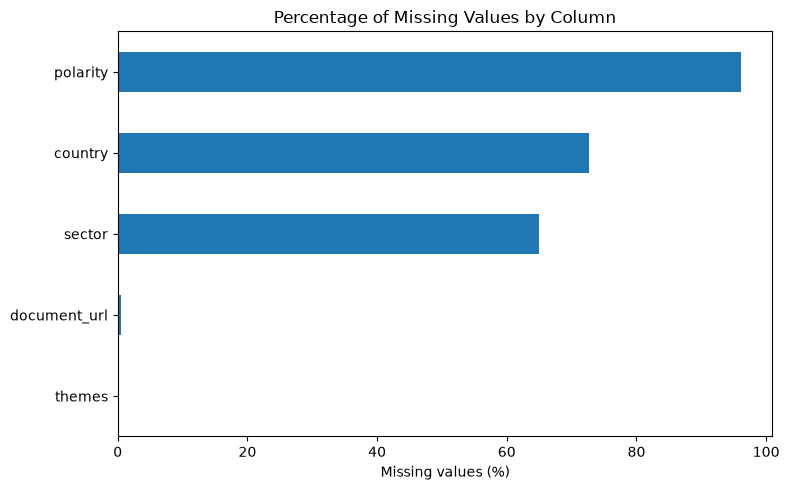

In [11]:
missing_pct = df.isnull().mean().mul(100)
missing_pct = missing_pct[missing_pct > 0].sort_values()

missing_pct.plot(kind="barh", figsize=(8, 5))

plt.xlabel("Missing values (%)")
plt.title("Percentage of Missing Values by Column")
plt.tight_layout()
plt.show()

 We have 6680 duplicates

In [12]:
dup  = sum(df.duplicated())
f"{dup} duplicates"

'6680 duplicates'

In [13]:
df.describe()

,sentence_id
count,117852.000000
mean,38.548230
std,94.186839
min,1.000000
25%,9.000000
50%,22.000000
75%,42.000000
max,2202.000000


#### Analysis of Numerical value : 

The dataset contains only one numerical column: `sentence_id`.

However, this column represents a sentence identifier rather than a quantitative variable. Therefore, statistical analysis such as mean, median, standard deviation, and numerical distribution is not meaningful.

It will instead be used as an identifier for sentence-level analysis when needed.

### Analysis of Categorial columns

### 01 - uri : Annotation Type

In [14]:
df['uri'].nunique()

13

In [15]:
uri_percentage  = df['uri'].value_counts(normalize=True, dropna=False).mul(100)
print(uri_percentage)

uri
Company               60.455487
MoneyAmount           24.521434
Date                  10.473306
CompanyPerformance     3.849744
CompanyAcquisition     0.227404
CompanyExpansion       0.179887
ProductLaunch          0.112005
CompanyWarning         0.068730
CompanyLawsuit         0.057699
CompanyDisruption      0.025456
CompanyPartnership     0.016970
CompanyClosure         0.010182
CompanyMerger          0.001697
Name: proportion, dtype: float64


In [16]:
uri_count = df["uri"].value_counts()
uri_ranking = uri_count.reset_index()

uri_ranking.columns = ["uri", "frequency"]
uri_ranking['rank'] = uri_ranking['frequency'].rank(ascending=False).astype(int)
uri_ranking


,uri,frequency,rank
0,Company,71248,1
1,MoneyAmount,28899,2
2,Date,12343,3
3,CompanyPerformance,4537,4
4,CompanyAcquisition,268,5
5,CompanyExpansion,212,6
6,ProductLaunch,132,7
7,CompanyWarning,81,8
8,CompanyLawsuit,68,9
9,CompanyDisruption,30,10


##### Top 10 annotation type

In [17]:
uri_count.head(10)

uri
Company               71248
MoneyAmount           28899
Date                  12343
CompanyPerformance     4537
CompanyAcquisition      268
CompanyExpansion        212
ProductLaunch           132
CompanyWarning           81
CompanyLawsuit           68
CompanyDisruption        30
Name: count, dtype: int64

In [18]:
rare_uri = uri_count[uri_count < 10]
rare_uri

uri
CompanyMerger    2
Name: count, dtype: int64

we can say so that for existing a row it must to have an uri  that's why there are zero missing values in the uri column.

In [19]:
print(f"Missing Values :",uri_count.isna().sum())


Missing Values : 0


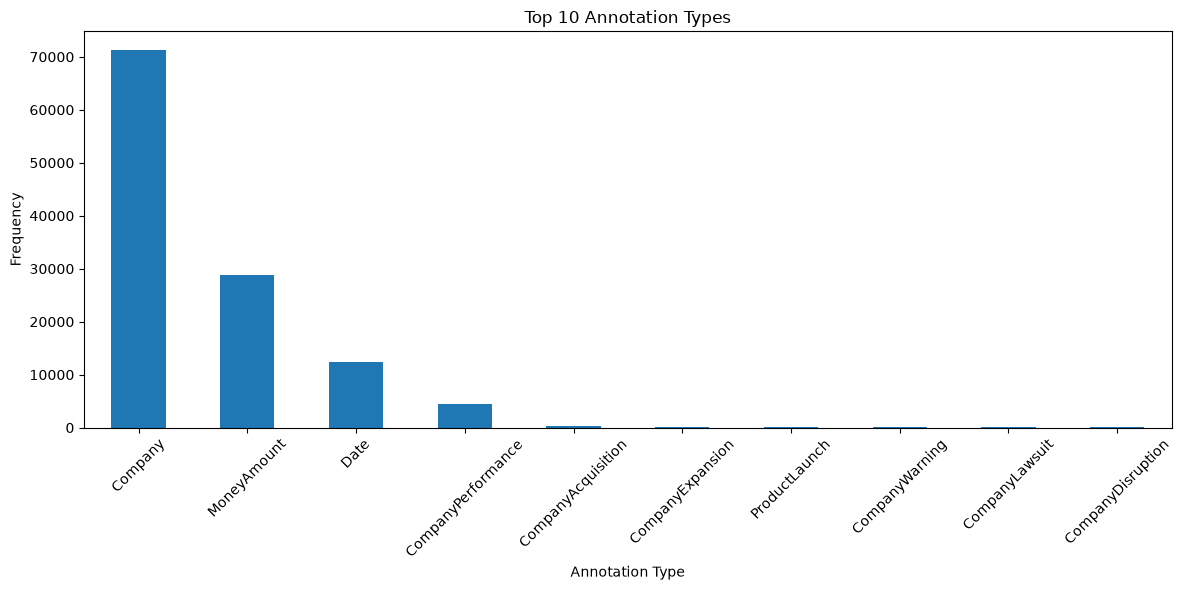

In [20]:
uri_top = df["uri"].value_counts().head(10)

plt.figure(figsize=(12, 6))

uri_top.plot(kind="bar")

plt.title("Top 10 Annotation Types")
plt.xlabel("Annotation Type")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

##### A significant imbalance.

In [21]:
valid_uri = df["uri"].value_counts()

imbalance_ratio = valid_uri.max() / valid_uri.min()

print("Imbalance ratio:", imbalance_ratio)

Imbalance ratio: 35624.0


Compraing between Common/rare types

In [22]:
uri_count.value_counts()

median = uri_count.median()

common_uri = uri_count[uri_count >= median]
rare_uri = uri_count[uri_count < median]

In [23]:
print("Common types:", len(common_uri))
print("Rare types:", len(rare_uri))

print("Common occurrences:", common_uri.sum())
print("Rare occurrences:", rare_uri.sum())

Common types: 7
Rare types: 6
Common occurrences: 117639
Rare occurrences: 213


2. Canonical : 

In [26]:
print(f"{df['canonical'].isna().sum()} duplicate")

0 duplicate
